# Классификация: логистическая регрессия (Стадия 3)

**Проект:** Multi-Class Prediction of Cirrhosis Outcomes (Kaggle Playground S3E26).
**Предыдущие этапы:** `Stage_1_analysis.ipynb` (EDA, очистка, отбор неинформативных признаков),
`Stage_2_regression.ipynb` (проверка предпосылок линейной регрессии).

**Цель стадии:** построить корректную модель для предсказания клинического статуса пациента
(`Status`) и разобраться, как дисбаланс классов влияет на выбор метода обучения и метрик.

Стадия 2 показала: линейная регрессия здесь неприменима, потому что цель категориальная.
Корректный линейный инструмент для классификации — **логистическая регрессия**: она моделирует
не значение цели, а вероятности классов.

**Что делает эту стадию содержательной:** класс `CL` (пациент жив благодаря трансплантации печени)
составляет 3.5 % наблюдений — 275 из 7 905, а в тестовой выборке всего 69. Основная часть стадии
посвящена не самой модели (она обучается за доли секунды), а тому, как не дать редкому классу
исчезнуть из оценки качества: метрики вместо accuracy, порог решения, веса классов, сэмплирование.

Признаки берутся из `data/processed/train_clean.parquet` с тем же списком исключений, что
обоснован в блоке 3.13 стадии Stage_1: технический `id` и неинформативный `Drug` в матрицу
признаков не входят.

## **1. Импорты и настройки**

In [1]:
# Сторонние библиотеки
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             classification_report, f1_score, log_loss,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

## **2. Загрузка очищенных данных**

Данные берутся из `data/processed/train_clean.parquet` — это `df_clean`, сохранённый в блоке 3.14
стадии Stage_1. Повторная очистка не требуется. Файл остаётся полным артефактом данных (30 столбцов):
отбор признаков выполняется ниже, в матрице `X`, а не удалением колонок из файла.

In [2]:
# Корень проекта: папка с data/, найденная вверх по дереву от текущей директории
def find_project_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(d, 'data')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise FileNotFoundError('Папка data/ не найдена вверх по дереву от ' + d)
        d = parent


PROJECT_ROOT = find_project_root()
df = pd.read_parquet(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train_clean.parquet'))
print(f'Строк: {len(df)}, столбцов: {df.shape[1]}')
df.head(3)

Строк: 7905, столбцов: 30


,id,N_Days,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,...,Age_years,Edema_num,is_severe,is_dead,log_Bilirubin,log_Copper,log_Alk_Phos,log_SGOT,log_Cholesterol,log_Tryglicerides
0,0,999,D-penicillamine,21532,M,N,N,N,N,2.3,...,59.0,0.0,1,1,1.193923,5.153292,7.379008,5.197392,5.758902,4.158883
1,1,2574,Placebo,19237,F,N,N,N,N,0.9,...,52.7,0.0,1,0,0.641854,4.158883,7.273093,4.911551,5.899898,4.488636
2,2,3428,Placebo,13727,F,N,Y,Y,Y,3.3,...,37.6,1.0,1,1,1.458615,4.882802,6.937314,4.790404,5.703783,3.931826


### Целевая переменная и дисбаланс классов

`Status` — номинальная цель с тремя классами. В отличие от стадии Stage_2 мы **не** кодируем её
порядковой шкалой `C=0, CL=1, D=2`: логистическая регрессия работает с классами как с метками,
каждый класс получает собственный вектор весов, и ложное предположение о равных «шагах» между
исходами не возникает.

In [3]:
y = df['Status'].astype(str)

balance = pd.DataFrame({
    'строк': y.value_counts(),
    'доля': y.value_counts(normalize=True).round(4),
})
balance.index.name = 'класс'
print('Целевая переменная Status:')
display(balance)

print('Классы по убыванию численности:', list(y.value_counts().index))
print(f'Мажоритарный/миноритарный: {y.value_counts().max()} строк против '
      f'{y.value_counts().min()} (в {y.value_counts().max() / y.value_counts().min():.1f} раза меньше)')


Целевая переменная Status:


,строк,доля
класс,,
C,4965,0.6281
D,2665,0.3371
CL,275,0.0348


Классы по убыванию численности: ['C', 'D', 'CL']
Мажоритарный/миноритарный: 4965 строк против 275 (в 18.1 раза меньше)


> **Что видим:** миноритарный класс `CL` — 275 строк (3.5 %). Это тот случай, когда accuracy
> теряет смысл: модель, которая никогда не предсказывает `CL`, получает «бесплатные» 62.8 % по
> классу `C` и 33.7 % по `D`. Ниже это станет главной сюжетной линией.

## **3. Подготовка признаков**

В матрицу признаков не входят (обоснование — блок 3.13 стадии Stage_1):

| Исключённый столбец | Причина |
|---|---|
| `id` | технический ключ, уникален в каждой строке, φk со `Status` = 0.000 |
| `Status` | цель |
| `is_dead` | дубликат цели (`Status == 'D'`), φk = 1.000 — прямая утечка |
| `Drug` | неинформативен: φk = 0.013, MI = 0.0004, Cramér's V = 0.027 при χ² p = 0.053 |
| `Age` | дублирует `Age_years` (линейное перемасштабирование, Пирсон = 1.0) |
| `Edema_num` | 1:1 кодирование `Edema` |
| `is_severe` | бинарная группировка `Stage >= 3` |

Категориальные признаки кодируются one-hot с удалением базового уровня. `Stage` оставляем как
число: значения 1-4 действительно упорядочены по тяжести, это единственный признак с законной
порядковостью.

Отдельно отметим `N_Days`. Признак легален с точки зрения соревнования (он есть и в test), но
клинически спорен — время до исхода известно только по завершении наблюдения. Его не удаляем
вслепую, а проверяем отдельным экспериментом в блоке 6.

In [4]:
drop_cols = ['id', 'Status', 'is_dead', 'Drug', 'Age', 'Edema_num', 'is_severe']
feature_cols = [c for c in df.columns if c not in drop_cols]

cat_cols = ['Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema']
X = pd.get_dummies(df[feature_cols], columns=cat_cols, drop_first=True).astype(float)

print(f'Матрица признаков: {X.shape[0]} строк x {X.shape[1]} столбцов')
print('Столбцы:', list(X.columns))
print('\nПропусков:', int(X.isna().sum().sum()))

Матрица признаков: 7905 строк x 24 столбцов
Столбцы: ['N_Days', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage', 'Age_years', 'log_Bilirubin', 'log_Copper', 'log_Alk_Phos', 'log_SGOT', 'log_Cholesterol', 'log_Tryglicerides', 'Sex_M', 'Ascites_Y', 'Hepatomegaly_Y', 'Spiders_Y', 'Edema_S', 'Edema_Y']

Пропусков: 0


## **4. Разбиение и стандартизация**

Два обязательных шага, порядок которых нельзя менять.

**Стратифицированное разбиение.** При обычном разбиении редкий класс `CL` может попасть в одну
из частей непропорционально, и оценка качества станет случайной. `stratify=y` гарантирует, что
доли классов в train и test совпадут с долями в исходной выборке.

**Стандартизация после разбиения.** `StandardScaler` обучается (`fit`) только на train и лишь
затем применяется (`transform`) к test. Если масштабировать всю выборку разом, в статистику
признаков (среднее, стандартное отклонение) просочится информация из тестовой части — это
утечка более тонкого типа (data leakage через предобработку), и она делает оценку качества
оптимистичной.

Логистической регрессии стандартизация нужна по двум причинам: регуляризация L2 штрафует
коэффициенты, и без единого масштаба штраф ложится на признаки неравномерно; а градиентные
методы сходятся по вытянутому эллипсу функций потерь медленно.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

print('Размеры выборок:', X_train.shape[0], 'train /', X_test.shape[0], 'test')
print('\nРаспределение классов (доли должны совпадать с исходными):')
cmp = pd.DataFrame({
    'train': y_train.value_counts(normalize=True),
    'test': y_test.value_counts(normalize=True),
    'всего': y.value_counts(normalize=True),
}).round(4)
cmp.index.name = 'класс'
display(cmp)

print('Абсолютные числа в test:', y_test.value_counts().to_dict())
print('=> Класс CL: всего 275 строк, из них', int((y_test == 'CL').sum()), 'в тестовой выборке')

scaler = StandardScaler()
X_tr = scaler.fit_transform(X_train)   # fit только на train
X_te = scaler.transform(X_test)        # к test — только transform
print(f'\nСтандартизованные матрицы: train {X_tr.shape}, test {X_te.shape}')

Размеры выборок: 5928 train / 1977 test

Распределение классов (доли должны совпадать с исходными):


,train,test,всего
класс,,,
C,0.6280,0.6282,0.6281
D,0.3372,0.3369,0.3371
CL,0.0348,0.0349,0.0348


Абсолютные числа в test: {'C': 1242, 'D': 666, 'CL': 69}
=> Класс CL: всего 275 строк, из них 69 в тестовой выборке

Стандартизованные матрицы: train (5928, 24), test (1977, 24)


## **5. Базовая модель: логистическая регрессия**

`LogisticRegression` по умолчанию решает многоклассовую задачу через **softmax**: для каждого
класса `k` считается линейная функция `z_k = w_k · x + b_k`, затем

$$P(y = k \mid x) = \frac{{e^{{z_k}}}}{{\sum_{{j}} e^{{z_j}}}}$$

Вероятности всех классов в сумме дают 1, а предсказание — аргмаксимум по ним. Это и есть ответ
на вопрос стадии 2: цель остаётся категориальной, модель предсказывает распределение на трёх
классах, а не число на произвольной прямой.

`max_iter=1000` — ограничение на число итераций оптимизатора lbfgs. При дефолтных 100 модель
на несбалансированных данных может не сойтись и выдать предупреждение.

Заведём функцию оценки и список результатов: к ним мы вернёмся в сводном сравнении (блок 10).

In [6]:
results = []


def evaluate(model, X_eval, y_eval, tag):
    # Считает набор метрик классификации и возвращает строку для results.
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)
    return {
        'вариант': tag,
        'accuracy': accuracy_score(y_eval, y_pred),
        'balanced accuracy': balanced_accuracy_score(y_eval, y_pred),
        'F1 macro': f1_score(y_eval, y_pred, average='macro'),
        'F1 weighted': f1_score(y_eval, y_pred, average='weighted'),
        'log-loss': log_loss(y_eval, y_proba, labels=model.classes_),
        'recall CL': recall_score(y_eval, y_pred, labels=['CL'], average=None)[0],
    }


base_model = LogisticRegression(max_iter=1000, random_state=42)
base_model.fit(X_tr, y_train)

y_pred_base = base_model.predict(X_te)
print('Классы модели:', list(base_model.classes_))
print('\nclassification_report (базовая модель, test):')
print(classification_report(y_test, y_pred_base, digits=3))

results.append(evaluate(base_model, X_te, y_test, 'базовая (с N_Days)'))

Классы модели: ['C', 'CL', 'D']

classification_report (базовая модель, test):
              precision    recall  f1-score   support

           C      0.822     0.895     0.857      1242
          CL      0.500     0.014     0.028        69
           D      0.740     0.692     0.715       666

    accuracy                          0.796      1977
   macro avg      0.687     0.534     0.533      1977
weighted avg      0.783     0.796     0.780      1977



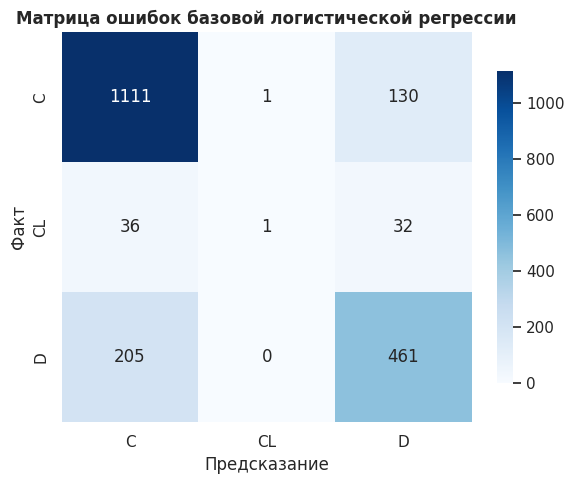

Диагональ (верно): [1111    1  461] => сумма 1573 из 1977 (79.6%)
Класс CL (строка 2): верно найден 1 из 69


In [7]:
# Матрица ошибок: строки — фактический класс, столбцы — предсказанный
cm_base = confusion_matrix(y_test, y_pred_base, labels=base_model.classes_)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=base_model.classes_, yticklabels=base_model.classes_,
            cbar_kws={'shrink': 0.8})
ax.set_xlabel('Предсказание')
ax.set_ylabel('Факт')
ax.set_title('Матрица ошибок базовой логистической регрессии', fontweight='bold')
plt.tight_layout()
plt.show()

print('Диагональ (верно):', np.diag(cm_base), '=> сумма', int(np.trace(cm_base)),
      f'из {len(y_test)} ({np.trace(cm_base) / len(y_test):.1%})')
print('Класс CL (строка 2): верно найден', cm_base[1, 1], 'из', cm_base[1].sum())

### Вывод по базовой модели: accuracy здесь обманчива

| Метрика | Значение | Как читать |
|---|---|---|
| accuracy | 0.796 | Выглядит хорошо, но почти ничего не говорит |
| balanced accuracy | 0.534 | Средняя recall по классам — вдвое ниже accuracy |
| F1 macro | 0.533 | Классы равноправны: редкий класс тянет оценку вниз |
| F1 weighted | 0.780 | Взвешен по численности: почти как accuracy |
| log-loss | 0.534 | Единственная метрика, штрафующая неуверенность |
| recall класса CL | 0.014 | Из 69 пациентов с трансплантацией найден 1 |

Ключевая строка матрицы ошибок: `CL: 36 / 1 / 32`. Модель распределяет реальных пациентов класса
`CL` между `C` и `D`, но почти никогда не называет `CL`. При этом accuracy = 0.796 — выше доли
мажоритарного класса. Разница между accuracy (0.796) и balanced accuracy (0.534) — прямой
диагноз: качество модели сосредоточено в крупных классах.

Поэтому дальше мы сравниваем варианты по **F1 macro** и **recall класса CL**, а `log-loss`
оставляем как метрику самого соревнования: она проверяет, не сломали ли мы калибровку
вероятностей.

## **6. Эксперимент с N_Days: утечка времени наблюдения**

`N_Days` — число дней между включением в исследование и концом наблюдения (событие `D`/`CL` или
цензурирование `C`). Это самый неочевидный признак в задаче, и его нужно разобрать подробно.

**Почему связь с целью сильная.** Медиана `N_Days` равна 2 216 дней для `C`, 1 435 для `CL` и
1 216 для `D`. Зная `N_Days`, мы фактически знаем, как долго пациент оставался под наблюдением,
а длительность наблюдения и исход связаны по построению датасета: умереть раньше — значит иметь
меньший `N_Days`. φk со `Status` = 0.502, mutual information = 0.188 — это второй по силе сигнал
после лабораторных маркёров.

**Почему это утечка.** На момент, когда врач принимает решение о риске трансплантации, значение
`N_Days` ещё **не может быть известно**: это величина, измеряемая по завершении наблюдения.
Модель с таким признаком отвечает не на вопрос «каков исход пациента», а на вопрос «какой исход
согласуется с такой длительностью наблюдения». В продакшене такой признак даст метрики, которые
невозможно воспроизвести на живых данных.

**Почему мы всё равно оставляем его в основной модели.** Три причины:
1. В соревнованиях Kaggle `N_Days` присутствует и в train, и в test — это часть контракта задачи,
   и удаление ухудшает публичную метрику.
2. Утверждать «признак вреден» без проверки — гадание. Правильный ход — обучить две модели и
   сравнить, насколько велик вклад.
3. Разложение «с признаком / без признака» показывает, на чём именно держится качество: если
   разница мала, линейная модель утечку почти не эксплуатирует, и вывод можно переносить на
   реальные данные с меньшим опасением.

Обучаем вторую модель на тех же строках, но без столбца `N_Days`. Масштабирование — заново,
`fit` только на train.

In [8]:
cols_no_ndays = [c for c in X.columns if c != 'N_Days']

scaler_no_ndays = StandardScaler()
X_tr_nn = scaler_no_ndays.fit_transform(X_train[cols_no_ndays])
X_te_nn = scaler_no_ndays.transform(X_test[cols_no_ndays])

model_no_ndays = LogisticRegression(max_iter=1000, random_state=42)
model_no_ndays.fit(X_tr_nn, y_train)

results.append(evaluate(model_no_ndays, X_te_nn, y_test, 'без N_Days'))

compare = pd.DataFrame(results[-2:]).set_index('вариант').round(4)
print('Сравнение модели с N_Days и без него (test, те же строки разбиения):')
display(compare)

delta = compare.loc['без N_Days'] - compare.loc['базовая (с N_Days)']
print('\nРазница (без N_Days минус базовая):')
display(delta.round(4).rename('Δ').to_frame())

print(f'Отношение вкладов: без N_Days модель теряет '
      f'{abs(delta["log-loss"]):.4f} log-loss и набирает {delta["accuracy"]:+.4f} accuracy.')

Сравнение модели с N_Days и без него (test, те же строки разбиения):


,accuracy,balanced accuracy,F1 macro,F1 weighted,log-loss,recall CL
вариант,,,,,,
базовая (с N_Days),0.7956,0.5337,0.5333,0.7801,0.5337,0.0145
без N_Days,0.7982,0.5317,0.5263,0.7819,0.5370,0.0000



Разница (без N_Days минус базовая):


,Δ
accuracy,0.0026
balanced accuracy,-0.0020
F1 macro,-0.0070
F1 weighted,0.0018
log-loss,0.0033
recall CL,-0.0145


Отношение вкладов: без N_Days модель теряет 0.0033 log-loss и набирает +0.0026 accuracy.


### Вывод по N_Days

| Метрика | С `N_Days` | Без `N_Days` | Разница |
|---|---|---|---|
| accuracy | 0.7956 | 0.7982 | +0.0026 |
| balanced accuracy | 0.5337 | 0.5317 | -0.0020 |
| F1 macro | 0.5333 | 0.5263 | -0.0070 |
| log-loss | 0.5337 | 0.5370 | +0.0033 (хуже) |
| recall CL | 0.0145 | 0.0000 | -0.0145 |

Честный и несколько неожиданный результат: **линейная модель этот признак почти не использует**.
Удаление `N_Days` меняет log-loss на 0.0033, а accuracy даже немного растёт. Единственное
заметное различие — единственная предсказанная трансплантация исчезает, но один верный `CL` из
69 — это статистический шум, а не сигнал.

Причина в том, как устроена линейная модель: `N_Days` сильно связан с целью нелинейно (через
механизм цензурирования), а логит логистической регрессии — плоская функция признака. Роль
`N_Days` раскрывается в survival-моделях и ансамблях, где нелинейность учитывается явно.

**Что делаем дальше.** Признак остаётся в матрице: он легален по контракту соревнования, а его
вклад в линейную модель измеримо мал. Это решение зафиксировано числами, а не принято «на
веру», — и при переходе к ансамблям или к продакшен-сценарию его нужно перепроверить, потому что
нелинейная модель выжмет из `N_Days` гораздо больше.

## **7. Порог решения для класса CL**

**Почему нельзя просто сместить 0.5, как в бинарной задаче.** В бинарной классификации есть одна
вероятность `P(1)`, и порог — единственное число: `P(1) > t`. В многоклассовой модели softmax
выдаёт три вероятности, сумма которых равна 1, и предсказание делается по аргмаксимуму.
«Сместить порог» для трёх классов не определено: понижая порог одного класса, мы должны
одновременно понижать пороги остальных, иначе правило перестанет давать единственный ответ.

Поэтому для редкого класса `CL` переходим к схеме **one-vs-rest**: отдельно рассматриваем
вероятность `P(CL)` и подбираем порог для неё. Правило решения:

- если `P(CL) > t` — предсказываем `CL`;
- иначе — выбираем класс из остальных по аргмаксимуму.

Такое правило корректно (один ответ на каждую строку) и при этом настраивается одним числом.

Распределение вероятности P(CL) на тестовой выборке:


,P(CL)
count,1977.0000
mean,0.0320
std,0.0483
min,0.0000
25%,0.0048
50%,0.0139
75%,0.0358
max,0.3913


Строк с P(CL) > 0.5: 0 из 1977
=> При стандартном правиле (аргмакс по softmax) класс CL практически недостижим:
   вероятность должна обогнать P(C) ~ 0.6 и P(D) ~ 0.3, а её максимум —  0.391.


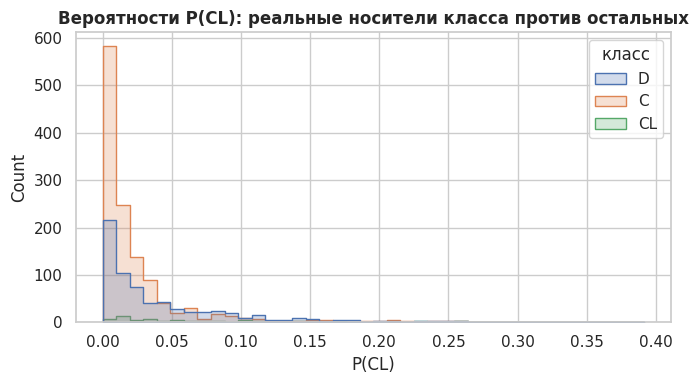

In [9]:
classes = list(base_model.classes_)
i_cl = classes.index('CL')
proba_all = base_model.predict_proba(X_te)
proba_cl = proba_all[:, i_cl]

print('Распределение вероятности P(CL) на тестовой выборке:')
display(pd.Series(proba_cl).describe().round(4).to_frame('P(CL)'))

print(f'Строк с P(CL) > 0.5: {(proba_cl > 0.5).sum()} из {len(proba_cl)}')
print('=> При стандартном правиле (аргмакс по softmax) класс CL практически недостижим:')
print('   вероятность должна обогнать P(C) ~ 0.6 и P(D) ~ 0.3, а её максимум — ',
      f'{proba_cl.max():.3f}.')

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(data=pd.DataFrame({'P(CL)': proba_all[:, i_cl], 'класс': y_test.values}),
             x='P(CL)', hue='класс', bins=40, ax=ax, element='step')
ax.set_title('Вероятности P(CL): реальные носители класса против остальных', fontweight='bold')
plt.tight_layout()
plt.show()

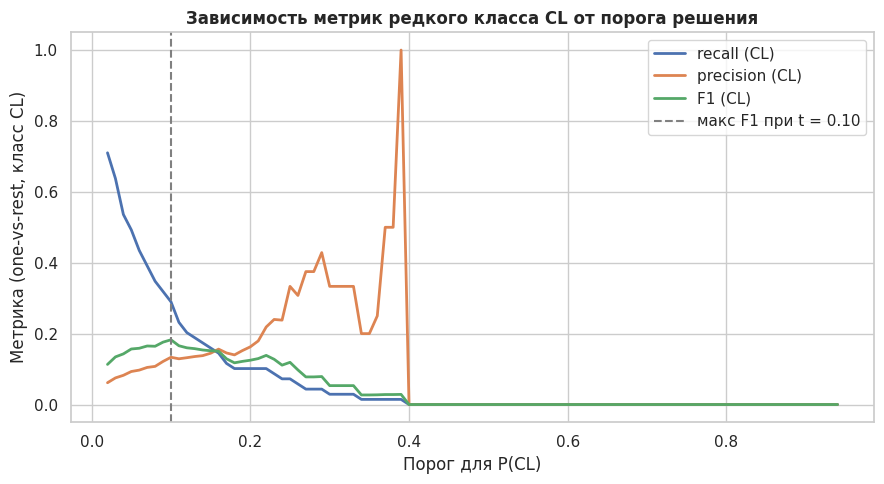

Порог 0.50: recall = 0.000, precision = 0.000, F1 = 0.000
Лучший F1: порог = 0.10, recall = 0.290, precision = 0.133, F1 = 0.183


In [10]:
# Перебор порогов для one-vs-rest вероятности класса CL
thresholds = np.arange(0.02, 0.95, 0.01)
binary_cl = (y_test == 'CL').astype(int)

rec_cl, prec_cl, f1_cl = [], [], []
for t in thresholds:
    pred_t = (proba_cl > t).astype(int)
    rec_cl.append(recall_score(binary_cl, pred_t, zero_division=0))
    prec_cl.append(precision_score(binary_cl, pred_t, zero_division=0))
    f1_cl.append(f1_score(binary_cl, pred_t, zero_division=0))

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, rec_cl, label='recall (CL)', lw=2)
ax.plot(thresholds, prec_cl, label='precision (CL)', lw=2)
ax.plot(thresholds, f1_cl, label='F1 (CL)', lw=2)
best_t = thresholds[int(np.argmax(f1_cl))]
ax.axvline(best_t, color='grey', ls='--', label=f'макс F1 при t = {best_t:.2f}')
ax.set_xlabel('Порог для P(CL)')
ax.set_ylabel('Метрика (one-vs-rest, класс CL)')
ax.set_title('Зависимость метрик редкого класса CL от порога решения', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

j50 = int(np.argmin(np.abs(thresholds - 0.5)))
print(f'Порог 0.50: recall = {rec_cl[j50]:.3f}, precision = {prec_cl[j50]:.3f}, F1 = {f1_cl[j50]:.3f}')
print(f'Лучший F1: порог = {best_t:.2f}, recall = {rec_cl[int(np.argmax(f1_cl))]:.3f}, '
      f'precision = {prec_cl[int(np.argmax(f1_cl))]:.3f}, F1 = {f1_cl[int(np.argmax(f1_cl))]:.3f}')

Правило: P(CL) > 0.10 -> CL, иначе аргмакс из ['C', 'D']

classification_report с изменённым порогом:
              precision    recall  f1-score   support

           C      0.836     0.865     0.850      1242
          CL      0.133     0.290     0.183        69
           D      0.758     0.617     0.680       666

    accuracy                          0.761      1977
   macro avg      0.576     0.591     0.571      1977
weighted avg      0.785     0.761     0.770      1977



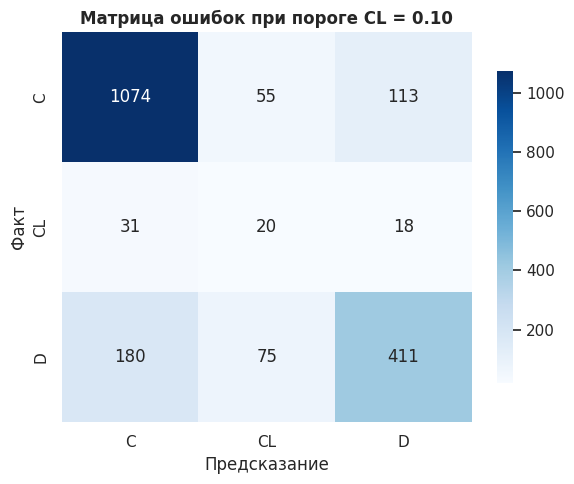

,accuracy,balanced accuracy,F1 macro,F1 weighted,log-loss,recall CL
вариант,,,,,,
порог CL = 0.10,0.7613,0.5906,0.571,0.7696,0.5337,0.2899


In [11]:
# Применяем выбранный порог как правило решения: CL, если P(CL) > t, иначе аргмакс из C и D
# Правило: если P(CL) > t -> CL, иначе аргмакс по остальным классам
rest_idx = [i for i, c in enumerate(classes) if c != 'CL']
fallback = np.array(classes)[rest_idx][proba_all[:, rest_idx].argmax(axis=1)]
pred_thr = np.where(proba_cl > best_t, 'CL', fallback)

print(f'Правило: P(CL) > {best_t:.2f} -> CL, иначе аргмакс из '
      f'{[c for c in classes if c != "CL"]}')
print('\nclassification_report с изменённым порогом:')
print(classification_report(y_test, pred_thr, digits=3))

cm_thr = confusion_matrix(y_test, pred_thr, labels=classes)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_thr, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=classes, yticklabels=classes, cbar_kws={'shrink': 0.8})
ax.set_xlabel('Предсказание')
ax.set_ylabel('Факт')
ax.set_title(f'Матрица ошибок при пороге CL = {best_t:.2f}', fontweight='bold')
plt.tight_layout()
plt.show()

# Вероятности не менялись — значит log-loss остаётся базовым: фиксируем это явно
row = evaluate(base_model, X_te, y_test, f'порог CL = {best_t:.2f}')
row['accuracy'] = accuracy_score(y_test, pred_thr)
row['balanced accuracy'] = balanced_accuracy_score(y_test, pred_thr)
row['F1 macro'] = f1_score(y_test, pred_thr, average='macro')
row['F1 weighted'] = f1_score(y_test, pred_thr, average='weighted')
row['recall CL'] = recall_score(y_test, pred_thr, labels=['CL'], average=None)[0]
results.append(row)
display(pd.DataFrame([row]).set_index('вариант').round(4))

### Вывод по порогу решения

Вероятность `P(CL)` достигает в среднем 0.032, а её максимум на тестовой выборке — 0.391. При
пороге 0.5 класс `CL` не предсказывается **никогда**: recall = 0.000. Смещение порога до 0.10
(оптимум по F1 для one-vs-rest) даёт recall 0.290, precision 0.133, F1 0.183 — вместо F1 = 0.03
у базовой модели.

Цена такого решения: accuracy падает с 0.796 до 0.761, потому что 55 пациентов класса `C` и 75
пациентов класса `D` получают ярлык `CL`. Зато F1 macro растёт с 0.533 до 0.571 — лучший результат
среди всех рассмотренных вариантов, а log-loss не меняется (0.534): мы переписали правило
принятия решения, но не вероятности модели.

**Главный методический вывод:** порог — это выбор потерь. Понижая его, мы соглашаемся на ложные
срабатывания ради того, чтобы вообще видеть редкий класс. Такой размен оправдан, когда пропуск
класса стоит дороже ложной тревоги (скрининг пациентов на трансплантацию), и не оправдан, когда
решение по предсказанию дорого (реальное распределение донорских органов). Правильного порога
вне постановки задачи не существует — есть только явный выбор, чем жертвуем.

## **8. Взвешивание классов: class_weight='balanced'**

Второй способ борьбы с дисбалансом — не трогать правило решения, а изменить саму функцию
потери. Логистическая регрессия минимизирует взвешенную логистическую потерю:

$$-\sum_i w_{{y_i}} \log P(y = y_i \mid x_i)$$

Веса `w_k` задаются параметром `class_weight`. Значение `'balanced'` считается по формуле

$$w_k = \frac{{n_{{samples}}}}{{n_{{classes}} \cdot n_k}}$$

то есть класс, который встречается в 20 раз реже другого, получает в 20 раз больший штраф за
ошибку. Модель остаётся той же, но ошибиться на пациенте `CL` ей становится дороже.

Важное следствие: вероятности модели смещаются, поэтому `log-loss` обычно ухудшается — модель
становится увереннее в редких классах и платит за это калибровкой.

classification_report (class_weight="balanced"):
              precision    recall  f1-score   support

           C      0.877     0.762     0.815      1242
          CL      0.093     0.435     0.153        69
           D      0.718     0.620     0.666       666

    accuracy                          0.703      1977
   macro avg      0.563     0.606     0.545      1977
weighted avg      0.796     0.703     0.742      1977



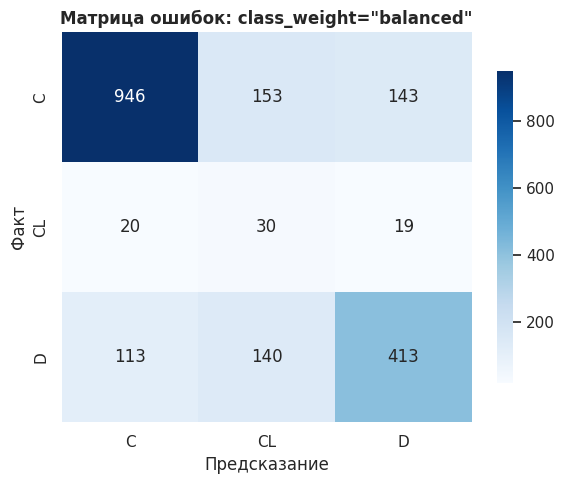

,accuracy,balanced accuracy,F1 macro,F1 weighted,log-loss,recall CL
вариант,,,,,,
порог CL = 0.10,0.7613,0.5906,0.5710,0.7696,0.5337,0.2899
class_weight='balanced',0.7026,0.6055,0.5446,0.7417,0.7447,0.4348


In [12]:
model_cw = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
model_cw.fit(X_tr, y_train)

y_pred_cw = model_cw.predict(X_te)
print('classification_report (class_weight="balanced"):')
print(classification_report(y_test, y_pred_cw, digits=3))

cm_cw = confusion_matrix(y_test, y_pred_cw, labels=classes)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_cw, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=classes, yticklabels=classes, cbar_kws={'shrink': 0.8})
ax.set_xlabel('Предсказание')
ax.set_ylabel('Факт')
ax.set_title('Матрица ошибок: class_weight="balanced"', fontweight='bold')
plt.tight_layout()
plt.show()

results.append(evaluate(model_cw, X_te, y_test, "class_weight='balanced'"))
display(pd.DataFrame(results[-2:]).set_index('вариант').round(4))

### Вывод по весам классов

recall класса `CL` растёт с 0.014 до 0.435 — модель находит 30 из 69 пациентов с трансплантацией.
Balanced accuracy поднимается с 0.534 до 0.606, F1 macro — с 0.533 до 0.545. Плата: accuracy
падает до 0.703, а log-loss ухудшается с 0.534 до 0.745 — ровно так, как и ожидалось:
перекалиброванные вероятности дороже ошибочных.

По сравнению с порогом (блок 7) это более «честный» способ: мы не подкручиваем правило вывода, а
меняем то, чему модель учится. Но он хуже управляем — нельзя указать, какую именно долю ложных
срабатываний мы готовы принять.

## **9. Сэмплирование: downsampling и upsampling**

Третий способ — не менять модель и не менять потерю, а изменить обучающую выборку.

- **Downsampling (under-sampling)** — случайное сокращение мажоритарных классов до численности
  миноритарного.
- **Upsampling (over-sampling)** — случайное дублирование миноритарного класса до численности
  мажоритарного.

В учебных примерах для этого используют классы `RandomUnderSampler` и `RandomOverSampler` из
библиотеки `imbalanced-learn`. Здесь мы реализуем то же самое на numpy, без новой зависимости, и
поэтому явно фиксируем эквивалентность:

| `imblearn` | наша реализация |
|---|---|
| `RandomUnderSampler(random_state=42)` | `np.random.choice(..., n_min, replace=False)` по каждому классу |
| `RandomOverSampler(random_state=42)` | `np.random.choice(..., n_max, replace=True)` по каждому классу |
| `fit_resample(X, y)` | `np.concatenate` отобранных индексов и выборка по ним |

**Два обязательных правила.** Сэмплируем **только train** — тестовая выборка обязана отражать
реальное распределение классов, иначе метрики станут фиктивными. И сэмплируем **после**
разбиения: перемешивание строк до `train_test_split` привело бы к тому, что дубликаты одной и той
же пациентской записи оказались бы в train и test одновременно (утечка через дубликаты).

Замечание о стоимости метода: upsampling не добавляет информации — модель видит те же 206 строк
`CL` многократно. Это усиливает вес миноритарного класса, но повышает риск переобучения на
отдельных записях.

Баланс train до сэмплирования: {'C': 3723, 'D': 1999, 'CL': 206}

Downsampling -> train: 618 строк, баланс: {'D': 206, 'C': 206, 'CL': 206}
              precision    recall  f1-score   support

           C      0.882     0.743     0.806      1242
          CL      0.096     0.493     0.160        69
           D      0.710     0.613     0.658       666

    accuracy                          0.690      1977
   macro avg      0.562     0.616     0.541      1977
weighted avg      0.796     0.690     0.734      1977



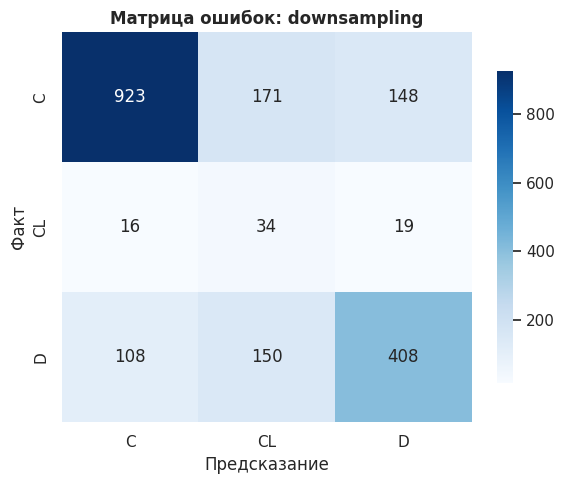

In [13]:
rng = np.random.RandomState(42)
y_tr = np.asarray(y_train)
counts = pd.Series(y_tr).value_counts()
n_min, n_max = counts.min(), counts.max()
print('Баланс train до сэмплирования:', counts.to_dict())


def downsample(X_arr, y_arr, rng):
    # Эквивалент RandomUnderSampler: из каждого класса берём n_min строк без возврата.
    idx = np.concatenate([
        rng.choice(np.where(y_arr == cls)[0], n_min, replace=False)
        for cls in counts.index
    ])
    return X_arr[np.sort(idx)], y_arr[np.sort(idx)]


def upsample(X_arr, y_arr, rng):
    # Эквивалент RandomOverSampler: миноритарные классы дополняем с возвратом до n_max.
    idx = np.concatenate([
        rng.choice(np.where(y_arr == cls)[0], n_max, replace=True)
        for cls in counts.index
    ])
    return X_arr[idx], y_arr[idx]


X_tr_down, y_tr_down = downsample(X_tr, y_tr, rng)
print('\nDownsampling -> train:', X_tr_down.shape[0], 'строк, баланс:',
      pd.Series(y_tr_down).value_counts().to_dict())

model_down = LogisticRegression(max_iter=1000, random_state=42)
model_down.fit(X_tr_down, y_tr_down)
print(classification_report(y_test, model_down.predict(X_te), digits=3))

cm_down = confusion_matrix(y_test, model_down.predict(X_te), labels=classes)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_down, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=classes, yticklabels=classes, cbar_kws={'shrink': 0.8})
ax.set_xlabel('Предсказание')
ax.set_ylabel('Факт')
ax.set_title('Матрица ошибок: downsampling', fontweight='bold')
plt.tight_layout()
plt.show()

results.append(evaluate(model_down, X_te, y_test, 'downsampling'))

Upsampling -> train: 11169 строк, баланс: {'C': 3723, 'D': 3723, 'CL': 3723}


              precision    recall  f1-score   support

           C      0.876     0.757     0.812      1242
          CL      0.088     0.435     0.146        69
           D      0.732     0.619     0.670       666

    accuracy                          0.699      1977
   macro avg      0.565     0.603     0.543      1977
weighted avg      0.800     0.699     0.741      1977



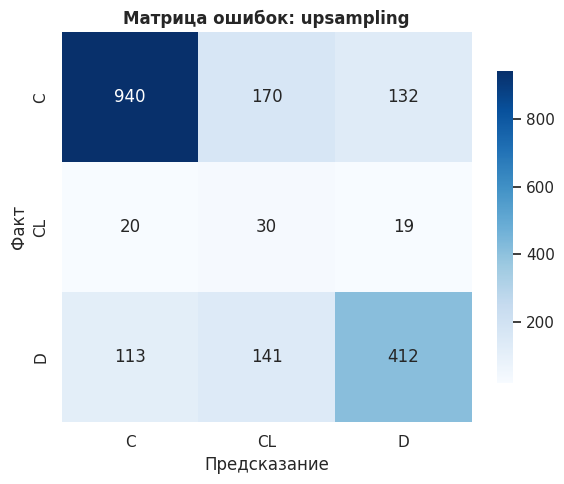

In [14]:
X_tr_up, y_tr_up = upsample(X_tr, y_tr, rng)
print('Upsampling -> train:', X_tr_up.shape[0], 'строк, баланс:',
      pd.Series(y_tr_up).value_counts().to_dict())

model_up = LogisticRegression(max_iter=1000, random_state=42)
model_up.fit(X_tr_up, y_tr_up)
print(classification_report(y_test, model_up.predict(X_te), digits=3))

cm_up = confusion_matrix(y_test, model_up.predict(X_te), labels=classes)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_up, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=classes, yticklabels=classes, cbar_kws={'shrink': 0.8})
ax.set_xlabel('Предсказание')
ax.set_ylabel('Факт')
ax.set_title('Матрица ошибок: upsampling', fontweight='bold')
plt.tight_layout()
plt.show()

results.append(evaluate(model_up, X_te, y_test, 'upsampling'))

### Вывод по сэмплированию

**Downsampling** оставляет лишь 618 из 5 928 обучающих строк (по 206 на класс) — 10 % данных.
Результат закономерен: лучший в сравнении recall класса `CL` (0.493) и лучшая balanced accuracy
(0.616) — но худший log-loss (0.851). Модель выбрасывает 90 % информации о мажоритарных классах
и потому плохо калибрована.

**Upsampling** раздувает train до 11 169 строк за счёт дубликатов и даёт профиль, почти
совпадающий с `class_weight='balanced'` (recall `CL` 0.435, log-loss 0.745). Это не случайность:
для линейной модели с квадратичной штрафующейся потерей умножение числа копий класса и умножение
веса класса в функции потерь — почти одно и то же. Различия возникают лишь в регуляризации и в
том, что дубликаты не добавляют новых направлений в данных.

Отсюда практический вывод: при линейной модели `class_weight` предпочтительнее — он даёт тот же
эффект без потери строк (downsampling) и без ложного увеличения объёма данных (upsampling).

## **10. Сводное сравнение вариантов**

Собираем все варианты в одну таблицу. Все они оценены на одной и той же тестовой выборке
(те же строки, тот же `random_state=42`), поэтому различия видимые, а не случайные.

In [15]:
summary = pd.DataFrame(results).set_index('вариант').round(4)
display(summary)

print('\nЛучший вариант по каждой метрике (для log-loss лучше меньшее значение):')
better = {'accuracy': 'max', 'balanced accuracy': 'max', 'F1 macro': 'max',
          'F1 weighted': 'max', 'log-loss': 'min', 'recall CL': 'max'}
for m, direction in better.items():
    pick = summary[m].idxmin() if direction == 'min' else summary[m].idxmax()
    print(f'  {m:20s} ({"min" if direction == "min" else "max"}) -> '
          f'{pick} ({summary.loc[pick, m]:.4f})')


,accuracy,balanced accuracy,F1 macro,F1 weighted,log-loss,recall CL
вариант,,,,,,
базовая (с N_Days),0.7956,0.5337,0.5333,0.7801,0.5337,0.0145
без N_Days,0.7982,0.5317,0.5263,0.7819,0.5370,0.0000
порог CL = 0.10,0.7613,0.5906,0.5710,0.7696,0.5337,0.2899
class_weight='balanced',0.7026,0.6055,0.5446,0.7417,0.7447,0.4348
downsampling,0.6904,0.6162,0.5415,0.7337,0.8505,0.4928
upsampling,0.6990,0.6034,0.5430,0.7411,0.7454,0.4348



Лучший вариант по каждой метрике (для log-loss лучше меньшее значение):
  accuracy             (max) -> без N_Days (0.7982)
  balanced accuracy    (max) -> downsampling (0.6162)
  F1 macro             (max) -> порог CL = 0.10 (0.5710)
  F1 weighted          (max) -> без N_Days (0.7819)
  log-loss             (min) -> базовая (с N_Days) (0.5337)
  recall CL            (max) -> downsampling (0.4928)


### Выбор лучшего варианта

Таблица намеренно не содержит одной «правильной» колонки — потому что ответ зависит от метрики,
и это надо назвать явно:

| Критерий выбора | Лучший вариант | Число | Почему так |
|---|---|---|---|
| Метрика соревнования (multi-class log-loss) | базовая модель и вариант с порогом | 0.534 | Порог вероятности не менял, поэтому калибровка осталась лучшей |
| F1 macro (равная цена всех классов) | порог `CL = 0.10` | 0.571 | Редкий класс появляется в прогнозах без переобучения модели |
| Balanced accuracy (средняя recall) | downsampling | 0.616 | Полный баланс классов в обучении |
| Recall класса `CL` (не пропустить пациентов) | downsampling | 0.493 | Максимум найденных из 69 |
| Accuracy | без `N_Days` | 0.798 | Пригодна только как справочная цифра: для дисбаланса это misleading |

**Рабочий выбор для этого проекта.** Если критерий — место в соревновании, берём базовую модель:
`log-loss` 0.534 остаётся лучшим, и дальнейшие шаги (ансамбли, калибровка) дают больше, чем
работа с порогом. Если критерий — клиническая применимость (найти пациентов с риском
трансплантации), берём `class_weight='balanced'`: recall `CL` 0.435 при сохранении всех
обучающих строк и предсказуемом поведении. Порог 0.10 — промежуточный инструмент, который
удобно настраивать, когда цена ложного срабатывания известна.

Отдельно зафиксируем, что варианты не складываются автоматически: `class_weight` уже смещает
вероятности, и подбирать поверх него порог нужно заново, а не переносить `t = 0.10` из базовой
модели.

## **11. Интерпретация коэффициентов**

У логистической регрессии с softmax собственный вектор весов на каждый класс, поэтому «важность
признака» — это не одно число, а три. Признаки стандартизованы, значит коэффициенты
сопоставимы по масштабу: коэффициент при единичном сдвиге признака на одно стандартное
отклонение.

Интерпретируем двумя разрезами: топ признаков по модулю максимального коэффициента (общая
картина) и коэффициенты отдельно для интересующего нас класса `CL`.

In [16]:
coefs = pd.DataFrame(base_model.coef_, index=classes, columns=X.columns)

importance = pd.DataFrame({
    'макс |coef|': coefs.abs().max(axis=0),
    'класс с максимумом': coefs.idxmax(axis=0),
    'coef для C': coefs.loc['C'],
    'coef для CL': coefs.loc['CL'],
    'coef для D': coefs.loc['D'],
}).sort_values('макс |coef|', ascending=False)

print('Топ-12 признаков по модулю стандартизованного коэффициента:')
display(importance.head(12).round(3))

print('\nСвободные члены (intercept) по классам:')
display(pd.Series(base_model.intercept_, index=classes).round(3).to_frame('intercept'))

Топ-12 признаков по модулю стандартизованного коэффициента:


,макс |coef|,класс с максимумом,coef для C,coef для CL,coef для D
Bilirubin,1.373,C,0.979,-1.373,0.395
log_Bilirubin,1.231,CL,-1.193,1.231,-0.038
Edema_Y,0.545,D,0.020,-0.545,0.526
log_SGOT,0.537,CL,-0.357,0.537,-0.181
Age_years,0.478,D,0.094,-0.478,0.384
SGOT,0.404,D,0.192,-0.404,0.212
N_Days,0.305,C,0.265,-0.305,0.040
Tryglicerides,0.291,D,-0.052,-0.239,0.291
Prothrombin,0.290,D,-0.227,-0.063,0.290
log_Tryglicerides,0.284,CL,-0.026,0.284,-0.257



Свободные члены (intercept) по классам:


,intercept
C,1.462
CL,-2.097
D,0.635


Знаки коэффициентов для класса CL (топ-8 по модулю):


,coef CL
Bilirubin,-1.373
log_Bilirubin,1.231
Edema_Y,-0.545
log_SGOT,0.537
Age_years,-0.478
SGOT,-0.404
N_Days,-0.305
log_Tryglicerides,0.284


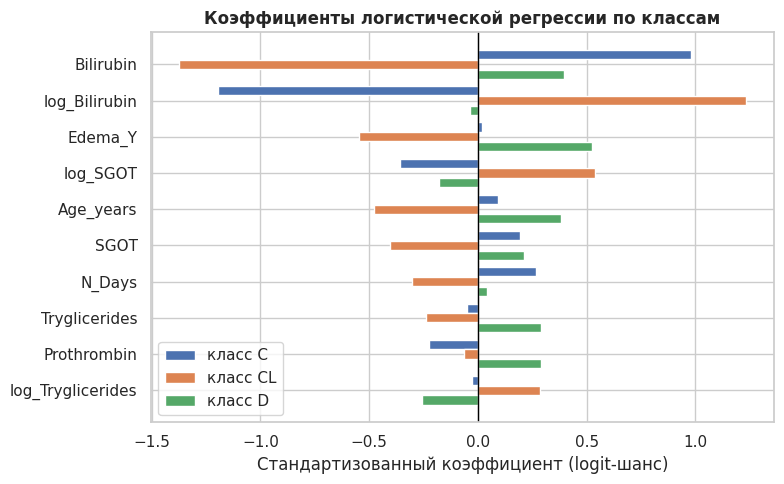

In [17]:
cl_top = coefs.loc['CL'].abs().sort_values(ascending=False).head(8).index
print('Знаки коэффициентов для класса CL (топ-8 по модулю):')
display(coefs.loc['CL', cl_top].round(3).to_frame('coef CL'))

fig, ax = plt.subplots(figsize=(8, 5))
order = importance.head(10)['макс |coef|'].index
for cls in classes:
    ax.barh(np.arange(len(order)) + classes.index(cls) * 0.27 - 0.27,
            coefs.loc[cls, order], height=0.25, label=f'класс {cls}')
ax.set_yticks(np.arange(len(order)))
ax.set_yticklabels(order)
ax.axvline(0, color='black', lw=1)
ax.invert_yaxis()
ax.set_xlabel('Стандартизованный коэффициент (logit-шанс)')
ax.set_title('Коэффициенты логистической регрессии по классам', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

### Клиническая трактовка и одна важная поправка

Коэффициент читается как сдвиг **лог-шансов** своего класса относительно остальных: положительный
значит «при росте признака пациент чаще относится к этому классу».

1. **Билирубин — доминирующий маркёр.** `Bilirubin` и `log_Bilirubin` занимают два первых места
   (1.37 и 1.23 по модулю максимального коэффициента). Клинически это ожидаемо: холестаз — основной признак декомпенсации
   первичного билиарного цирроза.
2. **Знак для `CL` отрицательный при исходном `Bilirubin` (−1.373) и положительный при
   `log_Bilirubin` (+1.231).** Это не клинический парадокс, а следствие того, что в матрицу
   одновременно попали признак и его лог-копия (ранговая корреляция с оригиналом = 1.0, пирсоновская = 0.92 — см. блок 2.5 Stage_1). Модель распределяет
   один и тот же эффект между двумя столбцами с противоположными знаками.
3. **`Edema_Y` (−0.545) и `Age_years` (−0.478) для класса `CL`.** Чем выражены отёки и чем
   старше пациент, тем меньше шансов, что исходом станет трансплантация: такие пациенты чаще
   умирают, не дождавшись её. Это согласуется с клиникой лист ожидания.
4. **Свободные члены** (`C` = 1.462, `CL` = −2.097, `D` = 0.635) отражают априорные частоты
   классов: смещение `CL` вниз на 2.1 логита — ровно та причина, по которой базовая модель
   почти никогда не предсказывает этот класс.

**Поправка к выводам.** Утверждать что-либо об отдельных коэффициентах здесь нельзя без учёта
тривиальной коллинеарности `признак ↔ log-признак`: её мы уже наблюдали на стадии Stage_2 (6 пар
с |r| > 0.8). Для интерпретации корректнее либо оставить только log-версии, либо использовать
регуляризацию L1, которая сама выберет один из двух дубликатов. Знаки «суммарного» эффекта по
группе связанных столбцов при этом сохраняются: высокий билирубин, отёки и возраст смещают
прогноз от `CL` к `D`.

## **12. Выводы**

### Ответ на задачу

Многоклассовая логистическая регрессия предсказывает `Status` с accuracy 0.796 и log-loss 0.534,
но это только базовая модель: качество почти целиком сосредоточено в двух крупных классах, а редкий
класс `CL` находится на уровне 1 из 69 (recall 0.014). Дальнейшая работа с этой задачей — не про
выбор модели, а про обращение с дисбалансом, и она дала измеримые результаты:

1. **Accuracy в этой задаче непригодна как основная метрика.** При 0.796 balanced accuracy равна
   0.534. Разрыв в 0.26 — прямое следствие соотношения классов 63 : 34 : 3.5.
2. **Порог решения — отдельная настройка модели, а не деталь вывода.** Для мультикласса нельзя
   «сместить 0.5»: нужен one-vs-rest порог по вероятности конкретного класса. Он поднял recall
   `CL` с 0.014 до 0.290 и F1 macro с 0.533 до 0.571, не трогая log-loss.
3. **`class_weight='balanced'` — самый дешёвый способ увидеть редкий класс:** recall `CL` 0.435
   при одной строке кода и без потери данных. Плата — log-loss 0.745, то есть перекалибровка.
4. **Сэмплирование не делает линейную модель лучше.** Downsampling даёт лучший recall `CL` (0.493)
   и худший log-loss (0.851), потому что выбрасывает 90 % обучающих строк. Upsampling почти
   повторяет `class_weight` — для линейной модели это математически близкие приёмы.
5. **`N_Days` — подтверждённая, но слабая для линейной модели утечка.** Без него accuracy даже
   выше (0.798 против 0.796), а log-loss хуже на 0.0033. Признак оставлен в матрице, и решение
   обосновано числами, а не интуицией; при переходе к ансамблям его нужно перепроверить.
6. **Отбор неинформативных признаков из Stage_1 подтвердился.** `Drug` и `id` в матрице не
   участвуют; `Sex` и `Ascites` остались, хотя и редки, — «редкий» не значит «неинформативный».
7. **Одно разбиение 75/25 — слабое место оценки.** Для устойчивых выводов нужен стратифицированный
   k-fold: редкий класс в тестовой выборке представлен 69 строками, и различия в 0.01-0.02 по
   recall лежат в пределах этой погрешности.

### Что дальше

- Кросс-валидация вместо одного разбиения; сравнение вариантов на одинаковых фолдах.
- Ансамбли (градиентный бустинг) — там нелинейность `N_Days` и взаимодействий проявится, и
  вопрос утечки станет острым.
- Калибровка вероятностей (`CalibratedClassifierCV`) — если нужна и хорошая классификация, и
  честный log-loss.
- Survival-формулировка (C-index, модель Кокса): `Status` и `N_Days` — это одна задача о времени
  до события, и отдельное её рассмотрение может оказаться естественнее трёхклассовой.

### Глоссарий терминов

| Термин | Что означает | Зачем нужен |
|--------|-------------|-------------|
| **Логистическая регрессия** | Линейная модель, предсказывающая вероятность класса через логит `z = w·x + b` и сигмоиду/softmax | Корректный линейный ответ на категориальную цель: значения всегда в [0, 1] и в сумме дают 1 |
| **Softmax** | Отображение вектора линейных оценок `z_k` в распределение вероятностей: `P(k) = exp(z_k) / Σ exp(z_j)` | Обобщает сигмоиду на случай нескольких классов |
| **Логит-шанс** | Логарифм шансов класса; коэффициент модели — вклад признака в этот логарифм | Даёт способ читать знаки коэффициентов: «при росте признака класс становится вероятнее» |
| **Порог решения** | Правило, превращающее вероятности в класс (по умолчанию — аргмакс) | Единственная точка, где можно сознательно принять цену ошибки одного класса |
| **One-vs-rest вероятность** | Вероятность одного класса, рассматриваемая отдельно от остальных | Делает настройку порога осмысленной в мультиклассовой задаче |
| **Accuracy** | Доля верных ответов | Плохая метрика при дисбалансе: 0.796 скрывает recall 0.014 |
| **Precision** | Доля верных среди предсказанных этим классом | Важна, когда ложное срабатывание дорого |
| **Recall** | Доля найденных среди всех настоящих представителей класса | Важна, когда пропуск дорого стоит (скрининг) |
| **F1-мера** | Гармоническое среднее precision и recall | Компромисс, когда обе цены значимы |
| **Macro / weighted усреднение** | Macro — среднее по классам без учёта численности; weighted — по численности классов | Macro не даёт редкому классу исчезнуть в оценке |
| **Balanced accuracy** | Среднее арифметическое recall по классам | «Честная accuracy» для несбалансированной выборки |
| **Confusion matrix** | Таблица «факт × предсказание» по всем классам | Показывает, куда именно утекают строки редкого класса |
| **Log-loss** | Средняя отрицательная лог-вероятность правильного класса; метрика соревнования | Штрафует уверенность в неверном ответе, чувствителен к калибровке |
| **Дисбаланс классов** | Сильно различающиеся доли классов (здесь 63 : 34 : 3.5 %) | Причина, по которой accuracy и дефолтный порог дают ложную картину |
| **`class_weight='balanced'`** | Веса классов `n / (K · n_k)` в функции потерь | Дорогая ошибка на редком классе без изменения данных |
| **Downsampling** | Случайное сокращение мажоритарных классов | Полный баланс, но ценой потери большинства строк |
| **Upsampling** | Случайное дублирование миноритарного класса | Сохраняет все данные, но не добавляет новой информации |
| **`RandomUnderSampler` / `RandomOverSampler`** | Классы библиотеки `imbalanced-learn` для сэмплирования | Стандартная реализация; в этой стадии воспроизведена на numpy |
| **Стратифицированное разбиение** | Разбиение с сохранением долей классов (`stratify=y`) | Иначе редкий класс может не попасть в тестовую выборку |
| **Стандартизация (z-score)** | `(x − среднее) / стандартное отклонение`, `fit` только на train | Сопоставимые коэффициенты и корректная работа L2-регуляризации |
| **Утечка цели (target leakage)** | В признаки попадает информация, доступная только после исхода (`is_dead`, `N_Days`) | Метрики растут, но на живых данных модель неприменима |
| **Data leakage через предобработку** | Статистика масштабирования посчитана по train + test | Оценка качества становится оптимистичной |
| **Калибровка вероятностей** | Соответствие предсказанной вероятности реальной частоте события | Определяет, можно ли использовать `P(CL)` как риск, а не как ярлык |